<a href="https://colab.research.google.com/github/KineticBlaze23/Metodos-Numericos/blob/main/Deber_interpolacion_taylor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



## ESCUELA POLITÉCNICA NACIONAL

---

## MÉTODOS NUMÉRICOS

### Deber: Interpolacion y polinomios de Taylor

---

**Estudiante:** Fabio Pillajo  
**Curso:** GR1 CC  
**Fecha:** 23 de noviembre de 2026

---
  


## 2. ¿Cuantos terminos necesita una calculadora?

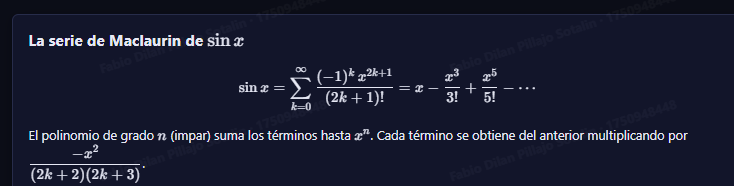

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Funcion de Taylor para sin(x)
def taylor_sin(x, n):
    """ Polinomio de Taylor de grado n de sin(x) para n impar"""

    if n < 1 or n % 2 == 0:
        raise ValueError("El grado n debe ser un entero impar positivo.")

    # Convertimos a arreglo flotante para soportar tanto escalares como arrays de NumPy
    x_arr = np.asarray(x, dtype=float)

    # Primer término (k = 0): x^1 / 1! = x
    termino = x_arr.copy()
    suma = termino.copy()

    # El grado n corresponde a k_max = (n - 1) // 2
    k_max = (n - 1) // 2
    for k in range(k_max):
        # Recurrencia dada: multiplicar por -x^2 / ((2k + 2)(2k + 3))
        termino = termino * (-x_arr**2) / ((2 * k + 2) * (2 * k + 3))
        suma = suma + termino

    # Si la entrada original era un número escalar, devolvemos un float
    if np.isscalar(x):
        return float(suma)
    return suma








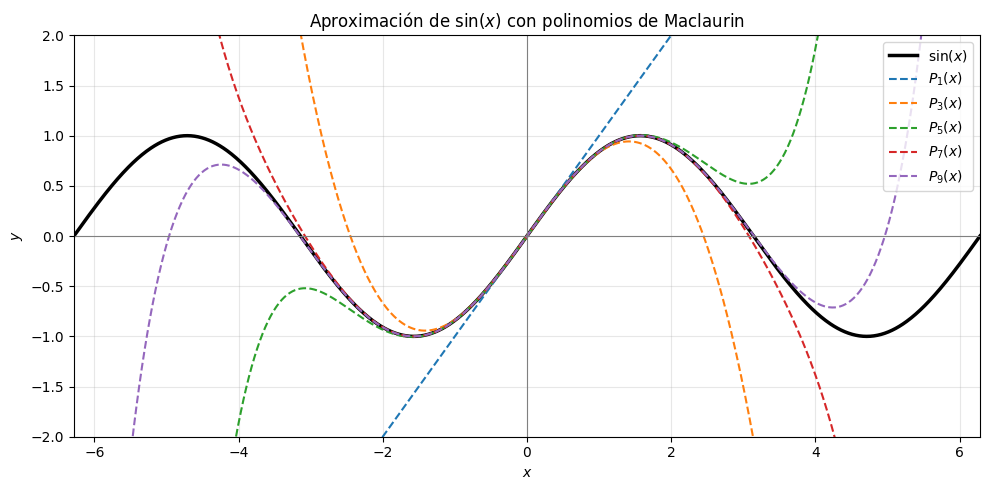

In [ ]:
#Grafica de sin(x) y de sus polinomio 1,3,5,7,9 en [-2pi, 2pi]
x1 = np.linspace(-2 * np.pi, 2 * np.pi, 1000)

plt.figure(figsize=(10, 5))
plt.plot(x1, np.sin(x1), 'k-', linewidth=2.5, label=r'$\sin(x)$')

for grado in [1, 3, 5, 7, 9]:
    plt.plot(x1, taylor_sin(x1, grado), '--', linewidth=1.5, label=f'$P_{{{grado}}}(x)$')

plt.ylim(-2, 2)
plt.xlim(-2 * np.pi, 2 * np.pi)
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.title(r'Aproximación de $\sin(x)$ con polinomios de Maclaurin')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
# Calculo de errores maximos
grados = np.arange(1, 22, 2)  # [1, 3, 5, ..., 21]

x_pi = np.linspace(-np.pi, np.pi, 2001)
x_pi4 = np.linspace(-np.pi / 4, np.pi / 4, 2001)

errores_pi = []
errores_pi4 = []

print(f"{'Grado n':>7} | {'Error max en [-π, π]':>22} | {'Error max en [-π/4, π/4]':>25}")
print("-" * 60)

for n in grados:
    err_1 = np.max(np.abs(np.sin(x_pi) - taylor_sin(x_pi, n)))
    err_2 = np.max(np.abs(np.sin(x_pi4) - taylor_sin(x_pi4, n)))

    errores_pi.append(err_1)
    errores_pi4.append(err_2)
    print(f"{n:>7d} | {err_1:>22.6e} | {err_2:>25.6e}")

Grado n |   Error max en [-π, π] |  Error max en [-π/4, π/4]
------------------------------------------------------------
      1 |           3.141593e+00 |              7.829138e-02
      3 |           2.026120e+00 |              2.454130e-03
      5 |           5.240439e-01 |              3.626459e-05
      7 |           7.522062e-02 |              3.116114e-07
      9 |           6.925271e-03 |              1.750320e-09
     11 |           4.451602e-04 |              6.928014e-12
     13 |           2.114257e-05 |              2.042810e-14
     15 |           7.727859e-07 |              2.220446e-16
     17 |           2.241951e-08 |              2.220446e-16
     19 |           5.289185e-10 |              2.220446e-16
     21 |           1.034798e-11 |              2.220446e-16


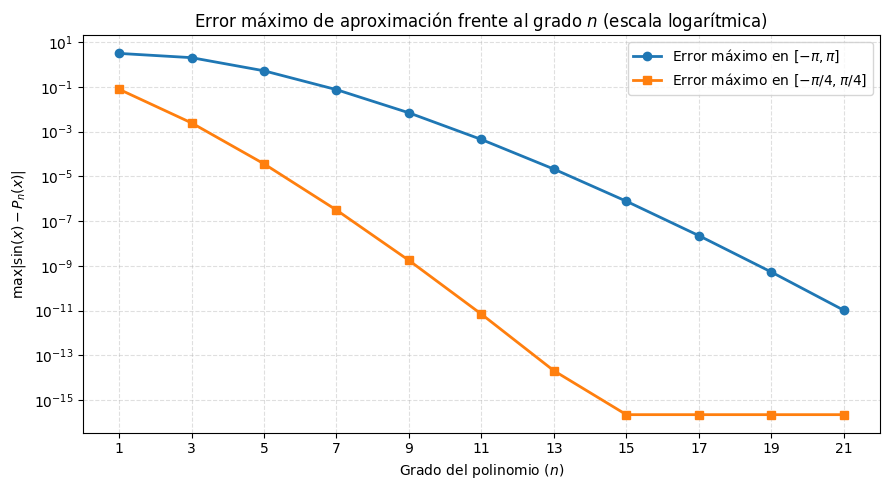

In [ ]:
# Grafica de errores maximos vs el grado
plt.figure(figsize=(9, 5))
plt.semilogy(grados, errores_pi, 'o-', linewidth=2, label=r'Error máximo en $[-\pi, \pi]$')
plt.semilogy(grados, errores_pi4, 's-', linewidth=2, label=r'Error máximo en $[-\pi/4, \pi/4]$')

plt.xticks(grados)
plt.title('Error máximo de aproximación frente al grado $n$ (escala logarítmica)')
plt.xlabel('Grado del polinomio ($n$)')
plt.ylabel(r'$\max|\sin(x) - P_n(x)|$')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#Calculo de p_9(pi)

P_9 = taylor_sin(np.pi , 9)
print(f"P_9(pi) = {P_9:.6f}")

P_9(pi) = 0.006925


## 3. Una funcion Suave cuya serie no converge

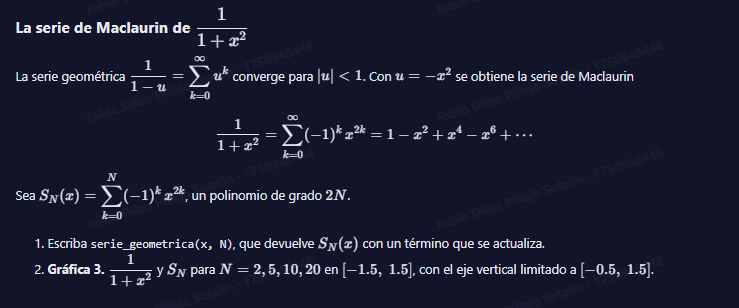

In [ ]:
# Funcion serie geometrica (x , N)
def serie_geometrica(x, N):
    """Calcula S_N(x)"""
    suma = 0
    termino = 1.0 + 0.0 * x  # Inicializamos el primer término en 1.0

    for k in range(N + 1):
        suma = suma + termino
        termino = termino * (-x**2)  # Cada término se obtiene multiplicando el anterior por -x^2

    return suma

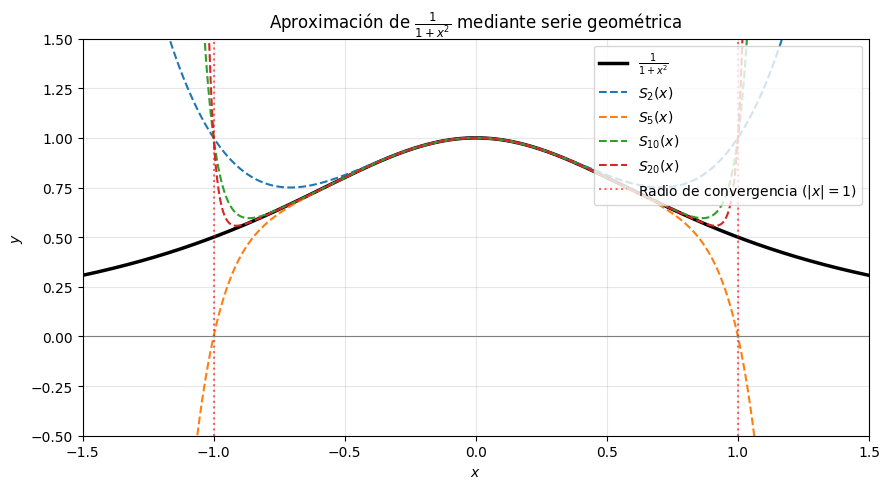

In [ ]:
# Grafica
x = np.linspace(-1.5, 1.5, 1000)
f_exacta = 1 / (1 + x**2)

plt.figure(figsize=(9, 5))
plt.plot(x, f_exacta, 'k-', linewidth=2.5, label=r'$\frac{1}{1 + x^2}$')

for N in [2, 5, 10, 20]:
    plt.plot(x, serie_geometrica(x, N), '--', linewidth=1.5, label=f'$S_{{{N}}}(x)$')

# Límites de los ejes y líneas de referencia
plt.xlim(-1.5, 1.5)
plt.ylim(-0.5, 1.5)
plt.axvline(-1, color='red', linestyle=':', alpha=0.6, label='Radio de convergencia ($|x|=1$)')
plt.axvline(1, color='red', linestyle=':', alpha=0.6)
plt.axhline(0, color='gray', linewidth=0.8)

plt.title(r'Aproximación de $\frac{1}{1 + x^2}$ mediante serie geométrica')
plt.xlabel('$x$')
plt.ylabel('$y$')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [ ]:
print("S_40(0.9) = " , serie_geometrica(0.9 , 40))

print("S_40(1.1) = " , serie_geometrica(1.1 , 40))


print("S_40(1.1) = " , serie_geometrica(1 , 50))
print("S_40(1.1) = " , serie_geometrica(1 , 60))
print("S_40(1.1) = " , serie_geometrica(1 , 70))

S_40(0.9) =  0.5525839582018942
S_40(1.1) =  1121.9747781214605
S_40(1.1) =  1.0
S_40(1.1) =  1.0
S_40(1.1) =  1.0


## 4. La serie correcta con la aritmética de la computadora

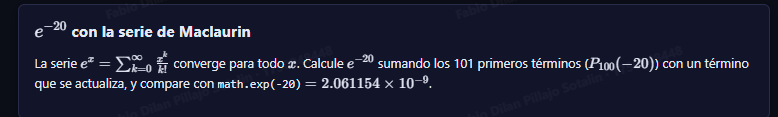

In [27]:
import math
def taylor_euler (x, n):
  suma = 0
  termino = 1
  for k in range(1, n+1):
      suma = suma + termino
      termino = termino * x / k
  return suma

print(taylor_euler(-20 , 100))
print(math.exp(-20))

5.621884472130418e-09
2.061153622438558e-09


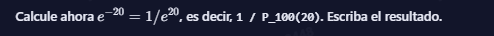

In [29]:
resultado = 1/taylor_euler(20, 100)
print(resultado)

2.0611536224385583e-09
